In [1]:
from pathlib import Path
from typing import Dict

import matplotlib.pyplot as plt
import pandas as pd
import torch
from torch.utils.data import DataLoader

from neuralhydrology.datasetzoo import get_dataset, camelsus
from neuralhydrology.datautils.utils import load_scaler
from neuralhydrology.modelzoo.cudalstm import CudaLSTM
from neuralhydrology.modelzoo.customlstm import CustomLSTM
from neuralhydrology.nh_run import start_run
from neuralhydrology.utils.config import Config

Intel MKL WARNING: Support of Intel(R) Streaming SIMD Extensions 4.2 (Intel(R) SSE4.2) enabled only processors has been deprecated. Intel oneAPI Math Kernel Library 2025.0 will require Intel(R) Advanced Vector Extensions (Intel(R) AVX) instructions.
Intel MKL WARNING: Support of Intel(R) Streaming SIMD Extensions 4.2 (Intel(R) SSE4.2) enabled only processors has been deprecated. Intel oneAPI Math Kernel Library 2025.0 will require Intel(R) Advanced Vector Extensions (Intel(R) AVX) instructions.


In [4]:
config_file = Path("../../config_files/test/test_generic_data.yml")
#run_dir = Path('runs/co_basins_NSE_loss_2006_090314')
run_dir = Path('runs/co_basins_NSE_loss_2006_091323')
#run_dir = Path('runs/co_basins_NSE_loss_1906_182901')
#run_dir = Path('runs/co_basins_QObs_antecedent')
#config_file = Path("/Users/joshsturtevant/Documents/lynker/projects/nasa_water/neuralhydrology/nasa_co_swe/job_scripts/test/runs/test_generic_data_1906_144823/config.yml")
!ls $run_dir/model_epoch* | tail -n 3

runs/co_basins_NSE_loss_2006_091323/model_epoch001.pt


In [5]:
cudalstm_config = Config(config_file)

# create a new model instance with random weights
cuda_lstm = CudaLSTM(cfg=cudalstm_config)

# load the trained weights into the new model.
model_path = run_dir / 'model_epoch001.pt'
model_weights = torch.load(str(model_path), map_location='cpu')  # load the weights from the file, creating the weight tensors on CPU
cuda_lstm.load_state_dict(model_weights)                         # set the new model's weights to the values loaded from file
cuda_lstm

CudaLSTM(
  (embedding_net): InputLayer(
    (statics_embedding): Identity()
    (dynamics_embedding): Identity()
  )
  (lstm): LSTM(25, 128)
  (dropout): Dropout(p=0.4, inplace=False)
  (head): Regression(
    (net): Sequential(
      (0): Linear(in_features=128, out_features=1, bias=True)
    )
  )
)

In [6]:
custom_lstm = CustomLSTM(cfg=cudalstm_config)  # create a new CustomLSTM (with random weights)
custom_lstm.copy_weights(cuda_lstm)  # copy the CudaLSTM weights into the CustomLSTM
custom_lstm

CustomLSTM(
  (embedding_net): InputLayer(
    (statics_embedding): Identity()
    (dynamics_embedding): Identity()
  )
  (cell): _LSTMCell()
  (dropout): Dropout(p=0.4, inplace=False)
  (head): Regression(
    (net): Sequential(
      (0): Linear(in_features=128, out_features=1, bias=True)
    )
  )
)

In [7]:
torch.allclose(cuda_lstm.lstm.bias_ih_l0, custom_lstm.cell.b_ih)

True

In [29]:
# make sure we're in eval mode where dropout is deactivated
custom_lstm.eval()
cuda_lstm.eval()

# load the dataset
scaler = load_scaler(run_dir)
dataset = get_dataset(cudalstm_config, is_train=False, period='test', scaler=scaler)
dataloader = DataLoader(dataset, batch_size=256, shuffle=False, collate_fn=dataset.collate_fn)

cudalstm_output = []
customlstm_output = []

# no need to calculate any gradients since we're just running some evaluations
with torch.no_grad():
    for sample in dataloader:
        #print(sample)
        customlstm_output.append(custom_lstm(sample))
        cudalstm_output.append(cuda_lstm(sample))

print('CudaLSTM output:  ', list(cudalstm_output[0].keys()))
print('CustomLSTM output:', list(customlstm_output[0].keys()))

# check if predictions of CustomLSTM and CudaLSTM are identical
print('Identical predictions:', torch.allclose(customlstm_output[0]['y_hat'], cudalstm_output[0]['y_hat'], atol=1e-5))

CudaLSTM output:   ['lstm_output', 'h_n', 'c_n', 'y_hat']
CustomLSTM output: ['h_n', 'c_n', 'i', 'f', 'g', 'o', 'y_hat']
Identical predictions: True


In [30]:
print('CudaLSTM shape:  ', cudalstm_output[0]['c_n'].shape)  # [batch size, 1, hidden size]
print('CustomLSTM shape:', customlstm_output[0]['c_n'].shape)  # [batch size, sequence length, hidden size]

# Concatenate all batches into one tensor that contains the final time step of each sample.
cell_states = torch.cat([out['c_n'][:, -1, :] for out in customlstm_output], dim=0)

# Load the forcings input for the corresponding date range
date_range = pd.date_range(cudalstm_config.test_start_date, cudalstm_config.test_end_date, freq='1D')

camels_dir = Path("/Users/joshsturtevant/Documents/lynker/projects/nasa_water/neuralhydrology/data/CAMELS_US")
forcings = camelsus.load_camels_us_forcings(camels_dir, '01022500', 'daymet')[0].loc[date_range]


CudaLSTM shape:   torch.Size([256, 1, 128])
CustomLSTM shape: torch.Size([256, 365, 128])


ValueError: x and y must have same first dimension, but have shapes (1461,) and torch.Size([20454, 128])

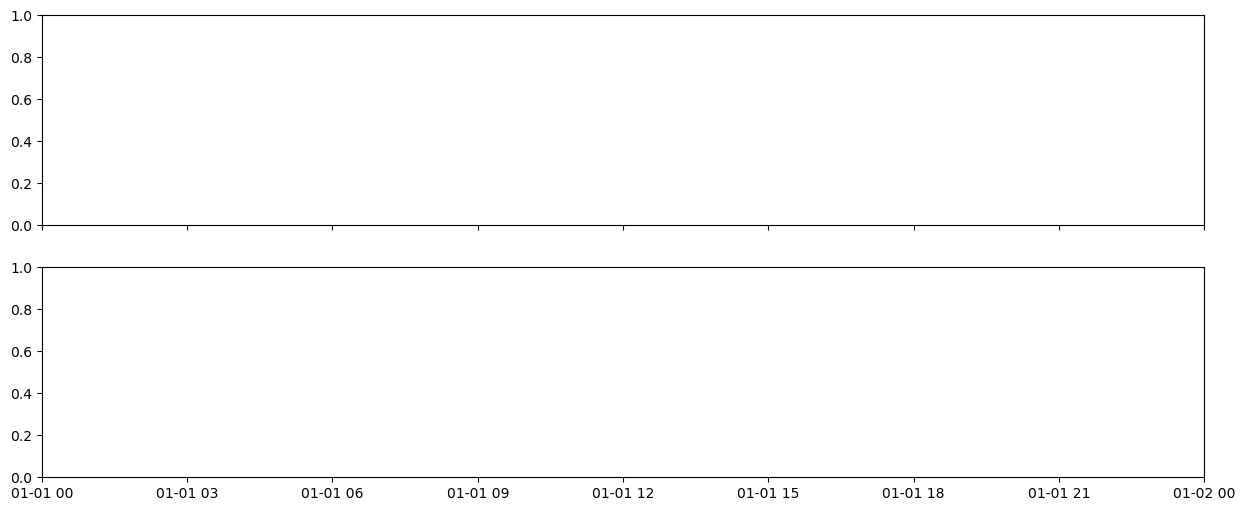

In [31]:
fig, (ax, ax2) = plt.subplots(2, 1, figsize=(15, 6), sharex=True)

ax.plot(date_range, cell_states, c='C0', alpha=.2)
ax.plot(date_range, cell_states[:, 7], c='C0')

ax.set_ylabel('cell state')
ax2.set_ylabel('min/max temperature')

#ax2.plot(date_range, forcings['tmin(C)'], c='C1')
#ax2.plot(date_range, forcings['tmax(C)'], c='C2')
plt.tight_layout()

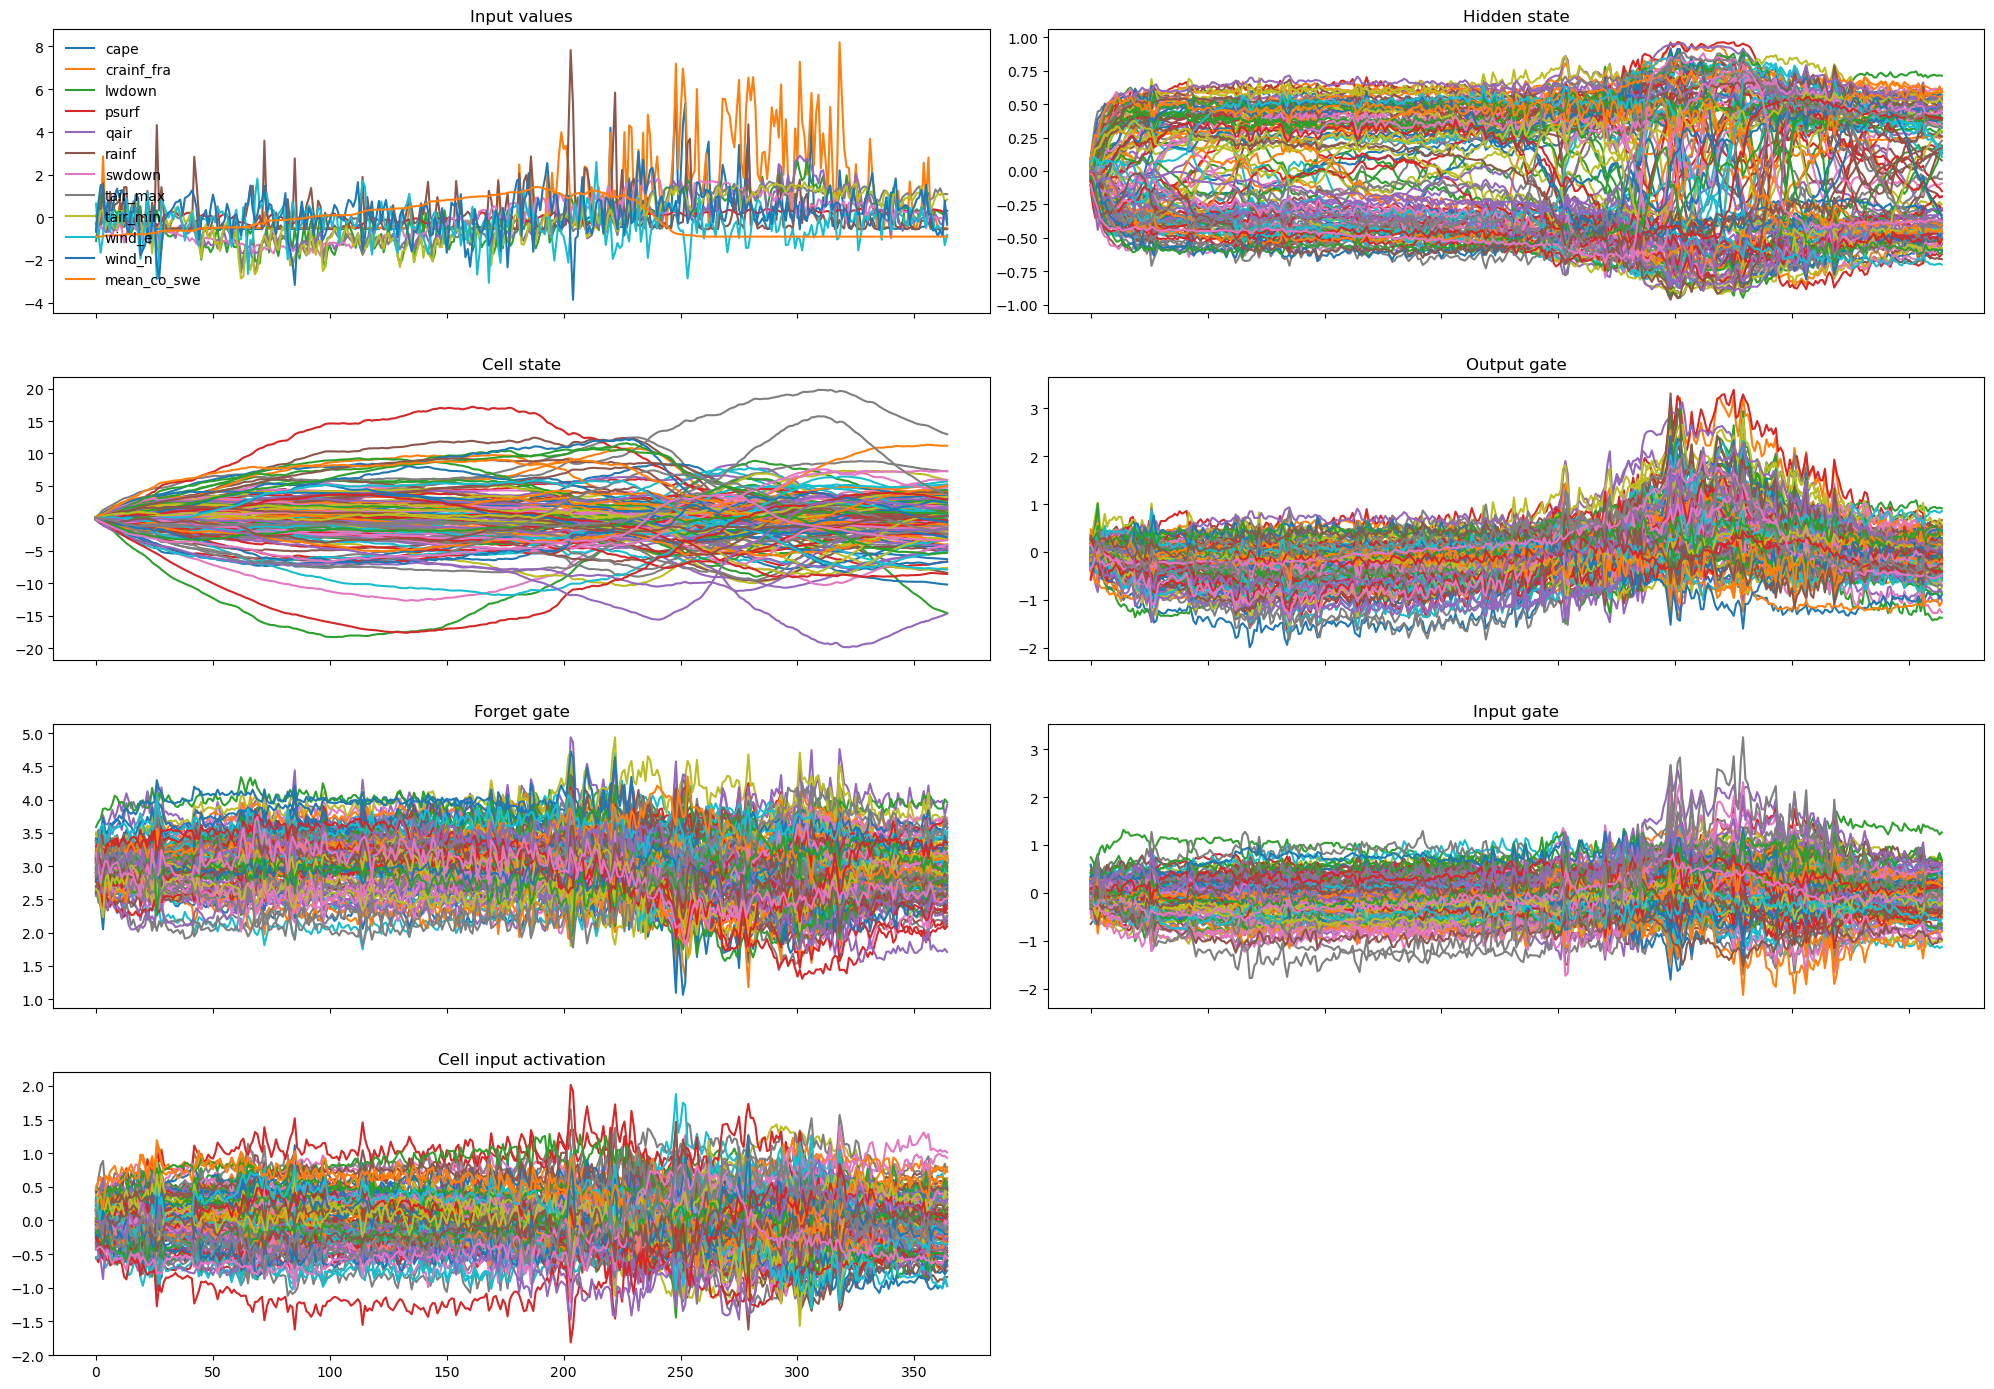

In [32]:
f, ax = plt.subplots(4, 2, figsize=(20, 14), sharex=True)
ax[0,0].set_title('Input values')
lines = ax[0,0].plot(dataset[0]['x_d'])  # these are the normalized inputs we fed the LSTM above
ax[0,0].legend(lines, cudalstm_config.dynamic_inputs, frameon=False, loc='upper left')

ax[1,0].set_title('Cell state')
ax[1,0].plot(customlstm_output[0]['c_n'][0])

ax[0,1].set_title('Hidden state')
ax[0,1].plot(customlstm_output[0]['h_n'][0])

ax[1,1].set_title('Output gate')
ax[1,1].plot(customlstm_output[0]['o'][0])

ax[2,0].set_title('Forget gate')
ax[2,0].plot(customlstm_output[0]['f'][0])

ax[2,1].set_title('Input gate')
ax[2,1].plot(customlstm_output[0]['i'][0])

ax[3,0].set_title('Cell input activation')
ax[3,0].plot(customlstm_output[0]['g'][0])

f.delaxes(ax[3,1])
plt.tight_layout()